# Heatmap for 5 stages

In [9]:
#Very useful examples of cooltools analysis and docs: https://cooltools.readthedocs.io/en/latest/notebooks/viz.html

#Import the packages we will use
#Utilities
import os
import re
import itertools
from itertools import combinations
import glob
import pickle
import argparse

#Data Management
import numpy as np
from numpy import diff
import pandas as pd
import h5py
import scipy
from scipy.stats import linregress
from scipy import ndimage
from functools import partial
from scipy.linalg import toeplitz

#Plotting
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib import cm
from matplotlib.gridspec import GridSpec
from matplotlib.gridspec import GridSpecFromSubplotSpec
import matplotlib.colors as colors
from matplotlib.colors import ListedColormap
from matplotlib.colors import LogNorm
from matplotlib.ticker import EngFormatter
from mpl_toolkits.axes_grid1 import make_axes_locatable
import seaborn as sns
import upsetplot
from upsetplot import UpSet

#Genomics
import pairtools
import cooler
import cooltools
# Import python package for working with cooler files and tools for analysis
import cooler
import bioframe
from bioframe import overlap
from cooltools import insulation

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Use bioframe to fetch the genomic features from the UCSC.
hg38_chromsizes = bioframe.fetch_chromsizes('hg38')
hg38_cens = bioframe.fetch_centromeres('hg38')
# create a view with chromosome arms using chromosome sizes and definition of centromeres
hg38_arms = bioframe.make_chromarms(hg38_chromsizes,  hg38_cens)

# load data

In [ ]:
#set path and condition of five stages
pathcool = "/home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/mcool_bulk"
conditions = [
    'ES',
    'DE',  
    'HB',
    'iHep',
    'mHep']

binsize =1000000

cooler_paths = { 
    'ES' : '{}/ESC-DdeI-DpnII-R1R2.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'DE' : '{}/DE-DdeI-DpnII-R1R2.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'HB' : '{}/HB-DdeI-DpnII-R1R2.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'iHep' : '{}/iHEP-DdeI-DpnII-R1R2.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'mHep' : '{}/mHEP-DdeI-DpnII-R1R2.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool)

}

long_names = { 
    'ES' : 'ES_rep12',
    'DE' : 'DE_rep12',  
    'HB' : 'HB_rep12',
    'iHep' : 'iHep_rep12',
    'mHep' : 'mHep_rep12'
}

clrs = {
    cond: cooler.Cooler(cooler_paths[cond]) for cond in conditions
}

samplePlotNames = {
    'ES' : 'ES',
    'DE' : 'DE',  
    'HB' : 'HB',
    'iHep' : 'iHep',
    'mHep' : 'mHep'
}

In [ ]:
#set bin size
bins = cooler.binnify(hg38_chromsizes, binsize)
#check the binsize again
clrs['mHep'].binsize

In [ ]:
#check the information
clrs['ES'].info

# Plot heatmap of intra chromosomal interactions

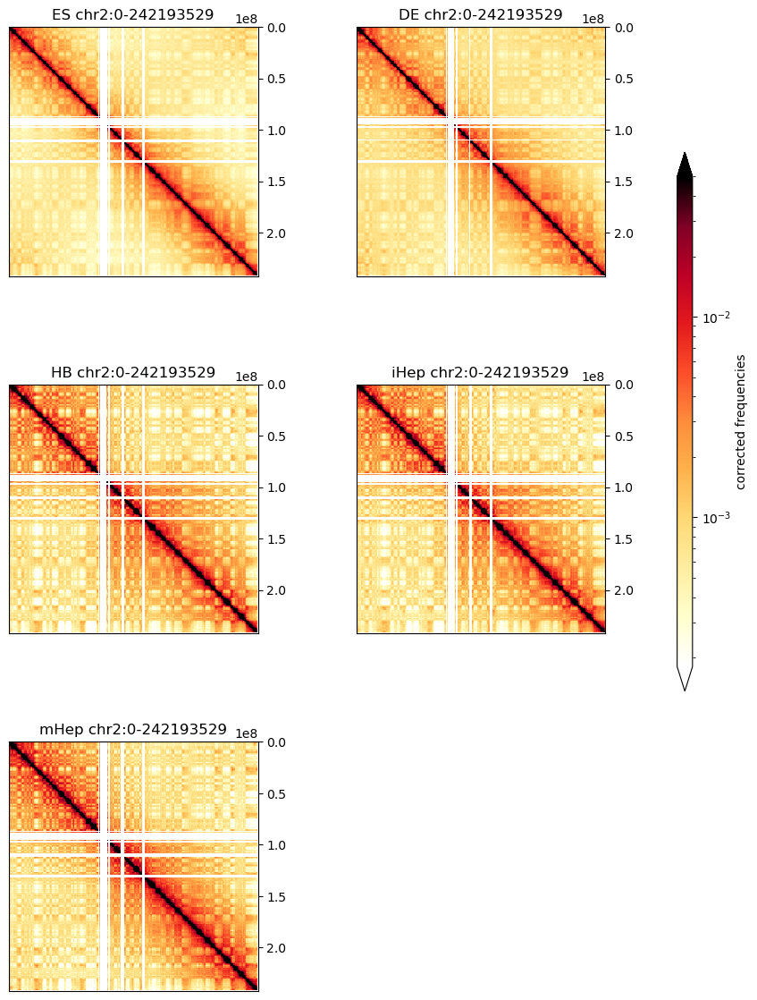

In [ ]:
#chr2 heatmap
plottingregion = 'chr2:0-242193529'
chromarm = ('chr2',0,242193529)

start = 0
#end = 100_000_000
end = 242193529
#region = ('chr4', start, end)
region = ('chr2', start, end)
norm = LogNorm(vmax=0.05) #set the scale range

fig = plt.figure(figsize=((4.5 * 2) + 1, 50))

gs00 = GridSpec(nrows = 3, ncols = 2, width_ratios = [20*2] + [1], wspace=0.2)

gs_cb = GridSpecFromSubplotSpec(nrows=2, ncols=1, height_ratios=[6, 1], wspace = 0.1, subplot_spec = gs00[1])

#how many heatmaps
gs0 = GridSpecFromSubplotSpec(nrows=3, ncols=2, wspace = 0.3, subplot_spec = gs00[0])

for i, cond in enumerate(conditions):
    gs1 = GridSpecFromSubplotSpec(nrows = 2, ncols = 1, height_ratios=[6, 1], wspace=0.1, 
                                  hspace = 0.05, subplot_spec = gs0[i])
        
    #plot heatmap
    ax = plt.subplot(gs1[0, 0])
    im = ax.matshow(
    clrs[cond].matrix().fetch(region),
    norm=norm,
    cmap='fall',
    extent=(start, end, end, start)
    );
    ax.xaxis.set_visible(False)
    ax.yaxis.tick_right()    
    ax.set_aspect('equal')
    plt.title(samplePlotNames[cond] + ' ' + plottingregion)
        
# color bar in it's own axis, and own gridspace
    colorAx = plt.subplot(gs_cb[0, 0])
    cb = plt.colorbar(im, cax = colorAx, extend = 'both')
    cb.set_label('corrected frequencies')
    
#plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot/Heatmap of 5stages {plottingregion}.pdf", 
#            format="pdf", bbox_inches="tight")


# Plot heatmap of intra and inter chromsomal interactions 

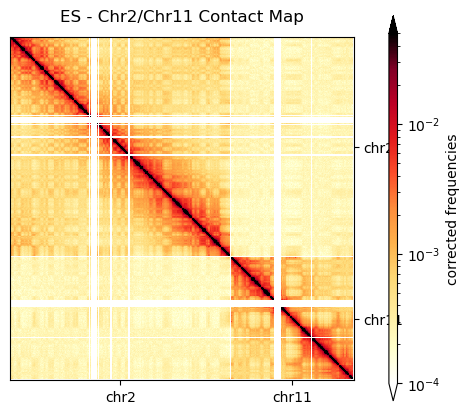

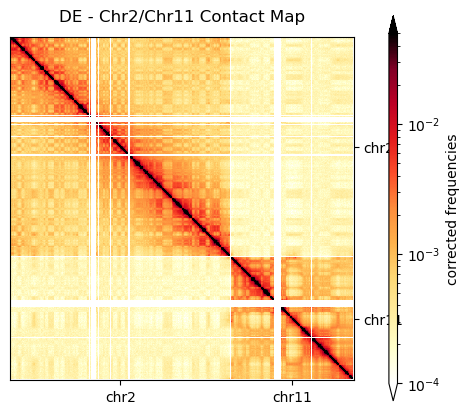

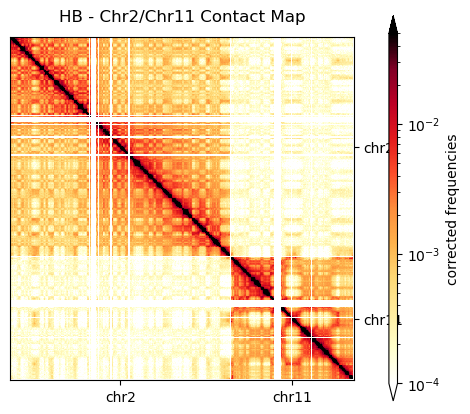

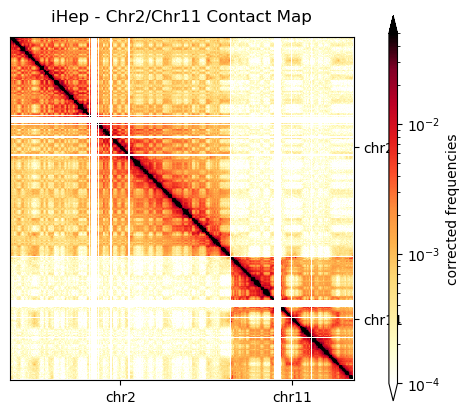

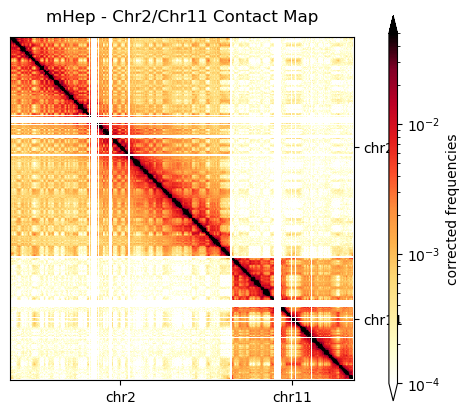

In [9]:
#layout chr2 and chr11 as square
start = 0
end = 242_193_529
region = ('chr2', start, end)
norm = LogNorm(vmin=1e-4, vmax=0.05)  # You can adjust vmin as needed
save_dir = "/home/xiangru.huo-umw/scHiC/scripts/plot"

chrom2 = 'chr2'
chrom11 = 'chr11'

for cond in conditions:
    clr = clrs[cond]
    
    # Fetch 4 blocks
    mat22 = clr.matrix(balance=True).fetch(chrom2, chrom2)
    mat21 = clr.matrix(balance=True).fetch(chrom2, chrom11)
    mat12 = clr.matrix(balance=True).fetch(chrom11, chrom2)
    mat11 = clr.matrix(balance=True).fetch(chrom11, chrom11)

    # Combine into 2x2 block
    top = np.hstack([mat22, mat21])
    bottom = np.hstack([mat12, mat11])
    full_matrix = np.vstack([top, bottom])

    # Sizes for extent in bp
    len2 = clr.chromsizes[chrom2]
    len11 = clr.chromsizes[chrom11]
    extent = [0, len2 + len11, len2 + len11, 0]

    # Set up layout
    fig = plt.figure(figsize=((4.5 * 1) + 0.5, 5))
    gs00 = GridSpec(nrows=1, ncols=2, width_ratios=[20*2, 1], wspace=0.2)
    gs_main = GridSpecFromSubplotSpec(nrows=1, ncols=1, subplot_spec=gs00[0])
    gs_cb = GridSpecFromSubplotSpec(nrows=1, ncols=1, subplot_spec=gs00[1])

    # Plot heatmap
    ax = plt.subplot(gs_main[0, 0])
    im = ax.matshow(
        full_matrix,
        norm=norm,
        cmap='fall',
        extent=extent
    )
    ax.set_xticks([len2/2, len2 + len11/2])
    ax.set_xticklabels([chrom2, chrom11])
    ax.set_yticks([len2/2, len2 + len11/2])
    ax.set_yticklabels([chrom2, chrom11])
    ax.xaxis.tick_bottom()
    ax.yaxis.tick_right()
    ax.set_title(f'{samplePlotNames[cond]} - Chr2/Chr11 Contact Map', y=1.02)
    ax.set_aspect('equal')

    # Colorbar
    colorAx = plt.subplot(gs_cb[0, 0])
    cb = plt.colorbar(im, cax=colorAx, extend='both')
    cb.set_label('corrected frequencies')
    
    # Save as PDF (one file per condition)
    save_path = os.path.join(save_dir, f"Heatmap_{cond}_chr2_chr11.pdf")
    plt.savefig(save_path, format="pdf", bbox_inches="tight")
    print(f"Saved: {save_path}")

    plt.show()

# plot heatmap of 8 DNA FISH loci 

In [2]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import EngFormatter
import matplotlib.patches as patches

In [3]:
#set path and condition of five stages
pathcool = "/home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/mcool_bulk"
conditions = ['ES', 'DE', 'HB', 'iHep', 'mHep']
binsize = 25_000  # Set uniform resolution for all

# Matching prefixes for the file names
prefixes = {
    'ES': 'ESC',
    'DE': 'DE',
    'HB': 'HB',
    'iHep': 'iHEP',
    'mHep': 'mHEP'
}

# Construct the cooler paths
cooler_paths = {
    cond: f"{pathcool}/{prefixes[cond]}-FA-DSG-DdeI-DpnII-R2L1-4__hg38.hg38.mapq_30.1000.mcool::resolutions/{binsize}"
    for cond in conditions
}

long_names = { 
    'ES' : 'ES_rep12',
    'DE' : 'DE_rep12',  
    'HB' : 'HB_rep12',
    'iHep' : 'iHep_rep12',
    'mHep' : 'mHep_rep12'
}

clrs = {
    cond: cooler.Cooler(cooler_paths[cond]) for cond in conditions
}

samplePlotNames = {
    'ES' : 'ES',
    'DE' : 'DE',  
    'HB' : 'HB',
    'iHep' : 'iHep',
    'mHep' : 'mHep'
}

In [4]:
# Define box regions, where "#" didn't used
box_regions = [
    ('chr11', 41_000_000, 41_500_000),
    ('chr11', 88_200_000, 88_400_000),
    ('chr11', 11_000_000, 12_000_000),
    ('chr11', 107_000_000, 109_000_000),
    ('chr11', 119_000_000, 120_000_000),
#    ('chr2', 79_325_001, 83_775_000),
    ('chr2', 2_000_000, 3_800_000),
    ('chr2', 100_400_000, 102_000_000),
#    ('chr2', 153_800_000, 154_500_000),
    ('chr2', 32_000_000, 32_500_000),
#    ('chr15', 25_100_000, 25_900_000),
#    ('chr15', 30_000_000, 31_000_000),
#    ('chr15', 34_900_000, 36_000_000),
#    ('chr15', 42_000_000, 42_600_000),
#    ('chr15', 50_400_000, 50_900_000),
#    ('chr15', 80_000_000, 81_000_000),
#    ('chr15', 85_500_000, 85_900_000),
#    ('chr15', 93_000_000, 94_000_000)   
]


/tmp/ipykernel_416194/2022905349.py:59: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.87, 1])


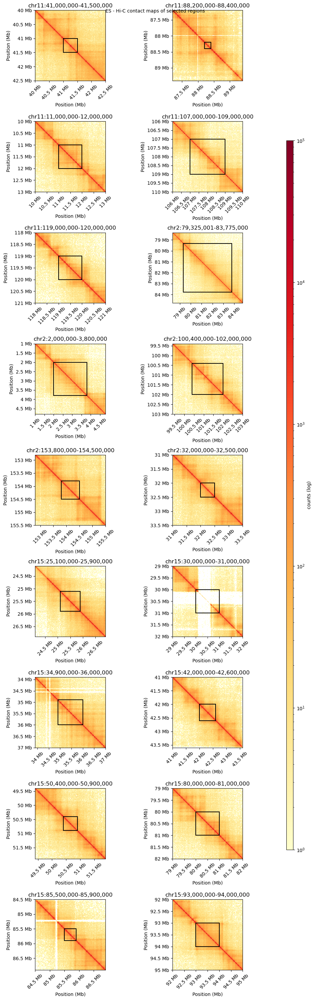

In [ ]:
#plot the heatmap of these regions
# Plot settings
cond = 'ES'
clr = clrs[cond]
norm = LogNorm(vmin=1, vmax=100_000)
bp_formatter = EngFormatter('b')

# Set up figure: 5 rows × 2 columns
fig, axs = plt.subplots(nrows=9, ncols=2, figsize=(10, 30))
axs = axs.flatten()

for i, (chrom, box_start, box_end) in enumerate(box_regions):
    ax = axs[i]

    # Define region around box (±2Mb)
    start = box_start - 1_000_000
    end = box_end + 1_000_000
    region = (chrom, start, end)

    # Fetch matrix
    matrix = clr.matrix(balance=False).fetch(region)

    # Plot matrix
    im = ax.matshow(
        matrix,
        norm=norm,
        cmap='YlOrRd',
        extent=(start, end, end, start)
    )

    # Format plot
    ax.set_title(f"{chrom}:{box_start:,}-{box_end:,}")
    ax.set_xlabel("Position (Mb)")
    ax.set_ylabel("Position (Mb)")
    ax.xaxis.set_major_formatter(bp_formatter)
    ax.yaxis.set_major_formatter(bp_formatter)
    ax.xaxis.tick_bottom()
    ax.tick_params(axis='x', rotation=45)
    ax.set_aspect('equal')

    # Draw black rectangle (box)
    box = patches.Rectangle(
        (box_start, box_start),
        box_end - box_start,
        box_end - box_start,
        linewidth=1.5,
        edgecolor='black',
        facecolor='none'
    )
    ax.add_patch(box)

# Add shared colorbar
fig.subplots_adjust(right=0.87)
cbar_ax = fig.add_axes([0.89, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("counts (log)")

fig.suptitle(f"{samplePlotNames[cond]} - Hi-C contact maps of selected regions", fontsize=10)
plt.tight_layout(rect=[0, 0, 0.87, 1])

plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot/Heatmap of loci for DNA FISH.pdf", 
            format="pdf", bbox_inches="tight")

plt.show()

# plot heatmap of different cell phase in H1

In [ ]:
#Merge different weight of G1, S, G2M cooler files together on command line
#1. determine the contacts number
#cooler info H1ESC_G1.hg38.mapq_30.1000.mcool::/resolutions/1000   （"sum": 217258193）
#cooler info H1ESC_S.hg38.mapq_30.1000.mcool::/resolutions/1000     （"sum": 220478147）
#cooler info H1ESC_G2M.hg38.mapq_30.1000.mcool::/resolutions/1000     （"sum": 199869875）

#2. Subsample according to their sorting ratio: G1:S:G2M = 0.4 : 0.2 : 0.4
#bsub -q short -W 8:00 -n 2 -R "rusage[mem=4000]" -R "span[hosts=1]" -oo sample3.out -eo sample3.err 'cooltools random-sample --frac 1 /home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/mcool_bulk/H1ESC_G2M.hg38.mapq_30.1000.mcool::/resolutions/1000  ./H1ESC_G2M.subset.cool'
#bsub -q short -W 8:00 -n 2 -R "rusage[mem=4000]" -R "span[hosts=1]" -oo sample2.out -eo sample2.err 'cooltools random-sample --frac 0.45 /home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/mcool_bulk/H1ESC_S.hg38.mapq_30.1000.mcool::/resolutions/1000  ./H1ESC_S.subset.cool'
#bsub -q short -W 8:00 -n 2 -R "rusage[mem=4000]" -R "span[hosts=1]" -oo sample1.out -eo sample1.err 'cooltools random-sample --frac 0.92 /home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/mcool_bulk/H1ESC_G1.hg38.mapq_30.1000.mcool::/resolutions/1000  ./H1ESC_G1.subset.cool'

#3. Merge the subset .cool
#bsub -q short -W 2:00 -n 2 -R "rusage[mem=4000]" -R "span[hosts=1]" -oo merge.out -eo merge.err "cooler merge H1ESC_merged_weighted_1kb.cool H1ESC_G1.subset.cool H1ESC_S.subset.cool H1ESC_G2M.subset.cool"

#4. cooler balance
#cooler balance H1ESC_merged_weighted_1kb.cool

#5. cooler zoomify
#bsub -q short -W 4:00 -n 2 -R "rusage[mem=8000]" -R "span[hosts=1]" -oo zoomify.out -eo zoomify.err "cooler zoomify --resolutions 1000N --balance /home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/mcool_bulk/H1ESC_merged_weighted.cool"

#6. mcooler balance
#cooler ls H1ESC_merged_weighted_1kb.mcool | xargs -n1 cooler balance

In [4]:
#set path and condition of 3 cell phase, and load the resolution = 1000000
pathcool = "/home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/mcool_bulk"
conditions = [
    'G1',
    'S',  
    'G2M',
    'weighted_merge'
]

binsize =1000000

cooler_paths = { 
    'G1' : '{}/H1ESC_G1.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'G2M' : '{}/H1ESC_G2M.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'S' : '{}/H1ESC_S.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'weighted_merge' : '{}/H1ESC_merged_weighted_1kb.mcool::resolutions/1000000'.format(pathcool)
}

long_names = { 
    'G1' : 'G1_rep12',
    'G2M' : 'G2M_rep12',  
    'S' : 'S_rep12',
    'weighted_merge' : 'weighted_merge'
}

clrs = {
    cond: cooler.Cooler(cooler_paths[cond]) for cond in conditions
}

samplePlotNames = {
    'G1' : 'G1',
    'S' : 'S',  
    'G2M' : 'G2-M',
    'weighted_merge' : 'weighted_merge'
}

In [5]:
#set bin size
bins = cooler.binnify(hg38_chromsizes, binsize)
#check the binsize again
clrs['G1'].binsize

1000000

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/Heatmap_G1_chr2_chr11.pdf


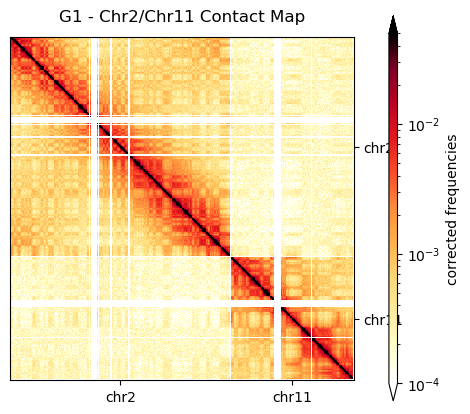

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/Heatmap_S_chr2_chr11.pdf


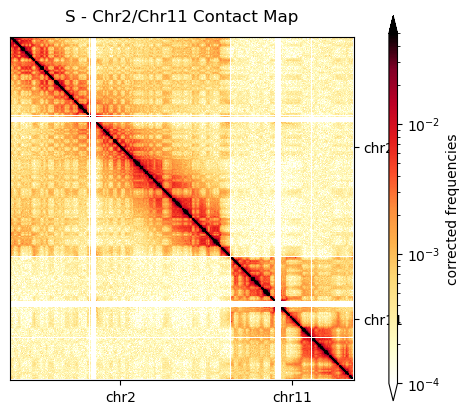

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/Heatmap_G2M_chr2_chr11.pdf


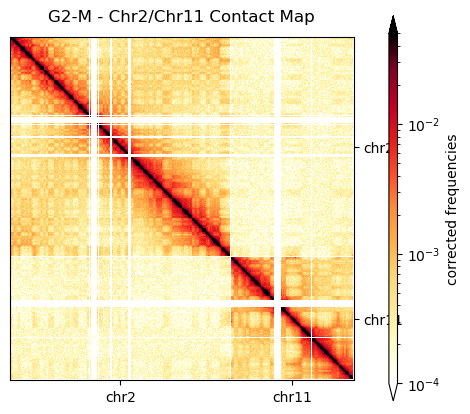

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/Heatmap_weighted_merge_chr2_chr11.pdf


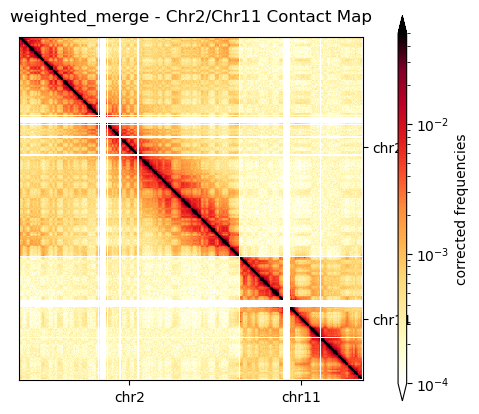

In [116]:
#layout chr2 and chr11 as square
start = 0
end = 242_193_529
region = ('chr2', start, end)
norm = LogNorm(vmin=1e-4, vmax=0.05)  # You can adjust vmin as needed
save_dir = "/home/xiangru.huo-umw/scHiC/scripts/plot"

chrom2 = 'chr2'
chrom11 = 'chr11'

for cond in conditions:
    clr = clrs[cond]
    
    # Fetch 4 blocks
    mat22 = clr.matrix(balance=True).fetch(chrom2, chrom2)
    mat21 = clr.matrix(balance=True).fetch(chrom2, chrom11)
    mat12 = clr.matrix(balance=True).fetch(chrom11, chrom2)
    mat11 = clr.matrix(balance=True).fetch(chrom11, chrom11)

    # Combine into 2x2 block
    top = np.hstack([mat22, mat21])
    bottom = np.hstack([mat12, mat11])
    full_matrix = np.vstack([top, bottom])

    # Sizes for extent in bp
    len2 = clr.chromsizes[chrom2]
    len11 = clr.chromsizes[chrom11]
    extent = [0, len2 + len11, len2 + len11, 0]

    # Set up layout
    fig = plt.figure(figsize=((4.5 * 1) + 0.5, 5))
    gs00 = GridSpec(nrows=1, ncols=2, width_ratios=[20*2, 1], wspace=0.2)
    gs_main = GridSpecFromSubplotSpec(nrows=1, ncols=1, subplot_spec=gs00[0])
    gs_cb = GridSpecFromSubplotSpec(nrows=1, ncols=1, subplot_spec=gs00[1])

    # Plot heatmap
    ax = plt.subplot(gs_main[0, 0])
    im = ax.matshow(
        full_matrix,
        norm=norm,
        cmap='fall',
        extent=extent
    )
    ax.set_xticks([len2/2, len2 + len11/2])
    ax.set_xticklabels([chrom2, chrom11])
    ax.set_yticks([len2/2, len2 + len11/2])
    ax.set_yticklabels([chrom2, chrom11])
    ax.xaxis.tick_bottom()
    ax.yaxis.tick_right()
    ax.set_title(f'{samplePlotNames[cond]} - Chr2/Chr11 Contact Map', y=1.02)
    ax.set_aspect('equal')

    # Colorbar
    colorAx = plt.subplot(gs_cb[0, 0])
    cb = plt.colorbar(im, cax=colorAx, extend='both')
    cb.set_label('corrected frequencies')
    
    # Save as PDF (one file per condition)
    save_path = os.path.join(save_dir, f"Heatmap_{cond}_chr2_chr11.pdf")
    plt.savefig(save_path, format="pdf", bbox_inches="tight")
    print(f"Saved: {save_path}")

    plt.show()

# call compartment at 1M bin of five stages and 3 cell phases. 

In [6]:
#get 1Mb matrix
#set path and condition of five stages
pathcool = "/home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/mcool_bulk"
conditions = [
    'ES',
    'DE',  
    'HB',
    'iHep',
    'mHep',
    'ES_G1',
    'ES_S',  
    'ES_G2M',
    'ES_weighted_merge'
]

binsize =1000000

cooler_paths = { 
    'ES' : '{}/ESC-DdeI-DpnII-R1R2.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'DE' : '{}/DE-DdeI-DpnII-R1R2.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'HB' : '{}/HB-DdeI-DpnII-R1R2.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'iHep' : '{}/iHEP-DdeI-DpnII-R1R2.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'mHep' : '{}/mHEP-DdeI-DpnII-R1R2.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'ES_G1' : '{}/H1ESC_G1.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'ES_G2M' : '{}/H1ESC_G2M.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'ES_S' : '{}/H1ESC_S.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'ES_weighted_merge' : '{}/H1ESC_merged_weighted_1kb.mcool::resolutions/1000000'.format(pathcool)
}

long_names = { 
    'ES' : 'ES_rep12',
    'DE' : 'DE_rep12',  
    'HB' : 'HB_rep12',
    'iHep' : 'iHep_rep12',
    'mHep' : 'mHep_rep12',
    'ES_G1' : 'ESG1_rep12',
    'ES_G2M' : 'ESG2M_rep12',  
    'ES_S' : 'ESS_rep12',
    'ES_weighted_merge' : 'ES_weighted_merge'
}

clrs = {
    cond: cooler.Cooler(cooler_paths[cond]) for cond in conditions
}

samplePlotNames = {
    'ES' : 'ES',
    'DE' : 'DE',  
    'HB' : 'HB',
    'iHep' : 'iHep',
    'mHep' : 'mHep',
    'ES_G1' : 'ES_G1',
    'ES_S' : 'ES_S',  
    'ES_G2M' : 'ES_G2M',
    'ES_weighted_merge' : 'ES_weighted_merge'
}

In [7]:
clrs['ES'].info

{'bin-size': 1000000,
 'bin-type': 'fixed',
 'creation-date': '2023-07-19T11:05:07.242499',
 'format': 'HDF5::Cooler',
 'format-url': 'https://github.com/mirnylab/cooler',
 'format-version': 3,
 'generated-by': 'cooler-0.8.5',
 'genome-assembly': 'unknown',
 'metadata': {},
 'nbins': 3103,
 'nchroms': 25,
 'nnz': 4266832,
 'storage-mode': 'symmetric-upper',
 'sum': 2125650482}

In [8]:
#GC density information
hg38_genome = bioframe.load_fasta('/home/xiangru.huo-umw/reference/hg38/hg38.fa');
gc_cov = bioframe.frac_gc(bins[['chrom', 'start', 'end']], hg38_genome)
gc_cov.to_csv('hg38_gc_cov_100kb.tsv',index=False,sep='\t')
gc_cov.head()

,chrom,start,end,GC
0,chr1,0,1000000,0.456540
1,chr1,1000000,2000000,0.572853
2,chr1,2000000,3000000,0.583712
3,chr1,3000000,4000000,0.564709
4,chr1,4000000,5000000,0.478991


In [9]:
#Get compartments, flip based on gene density, good chroms by arm only
#Not sorting by variance compared to gene density, instead by variance explained of data
lam = {}
eigs = {}

for cond in conditions:
    lam[cond], eigs[cond] = cooltools.eigs_cis(
        clrs[cond], 
        gc_cov,
        n_eigs=3, 
        ignore_diags=2,
        view_df = hg38_arms
    )

In [10]:
for cond in conditions:
    # Save text files
    lam[cond].to_csv(f'{pathcool}/{long_names[cond]}.{binsize//1000000}kb.2combo.eigs.cis.lam.txt', sep='\t')
    eigs[cond].to_csv(f'{pathcool}/{long_names[cond]}.{binsize//1000000}kb.2combo.eigs.cis.vecs.txt', sep='\t', index=False)
    # Save bedGraph track
    eigs[cond][['chrom', 'start', 'end', 'E1']].to_csv(f'{pathcool}/{long_names[cond]}.{binsize//1000000}kb.2combo.mapq30.byarm.eigs.cis.vecs.E1.bedGraph', sep='\t', index=False, header = False) 

In [11]:
eigs[cond]

,chrom,start,end,weight,E1,E2,E3
0,chr1,0,1000000,NaN,NaN,NaN,NaN
1,chr1,1000000,2000000,0.003450,0.733490,-0.151760,0.175548
2,chr1,2000000,3000000,0.004456,0.559427,-0.006469,0.154860
3,chr1,3000000,4000000,0.003287,0.531629,-0.030921,0.123950
4,chr1,4000000,5000000,0.003731,0.223811,0.008717,0.009830
...,...,...,...,...,...,...,...
3098,chrY,54000000,55000000,NaN,NaN,NaN,NaN
3099,chrY,55000000,56000000,NaN,NaN,NaN,NaN
3100,chrY,56000000,57000000,NaN,NaN,NaN,NaN
3101,chrY,57000000,57227415,NaN,NaN,NaN,NaN


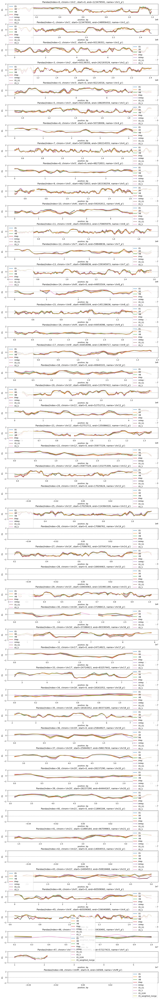

In [124]:
#plot eig1 for each region to make sure they were detecting compartments and not something else...
fig = plt.figure(figsize=(15, 2 * len(hg38_arms)))

gs1 = GridSpec(nrows = len(hg38_arms), ncols = 1, hspace = 0.8)

for i, arm in enumerate(hg38_arms.itertuples()):
    ax = plt.subplot(gs1[i])
    for cond in conditions:
        loc_eig = bioframe.select(eigs[cond], arm[1:4])
        ax.plot(
            loc_eig['start'],
            loc_eig['E1'],
            label = cond
        )
        plt.axhline(0,ls='--',lw=0.5,color='gray')
        plt.ylabel('E1')
        plt.xlabel('position, bp')
        plt.title(arm)
        plt.legend()
        plt.ylim(-2, 2)

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/EGV1_ES_chr2_chr11.pdf


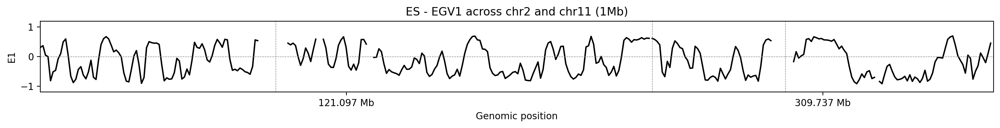

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/EGV1_DE_chr2_chr11.pdf


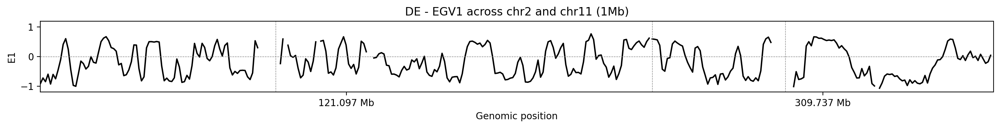

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/EGV1_HB_chr2_chr11.pdf


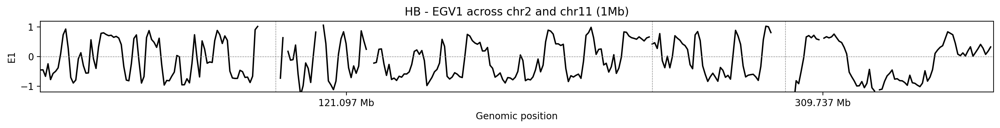

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/EGV1_iHep_chr2_chr11.pdf


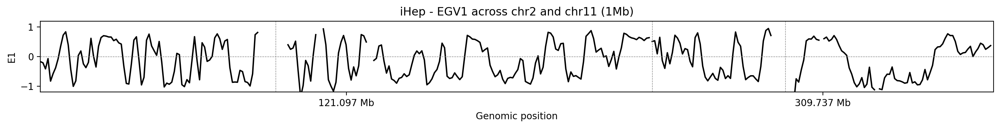

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/EGV1_mHep_chr2_chr11.pdf


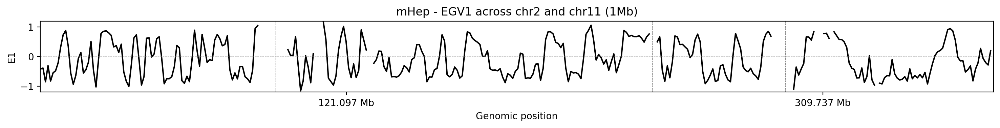

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/EGV1_ES_G1_chr2_chr11.pdf


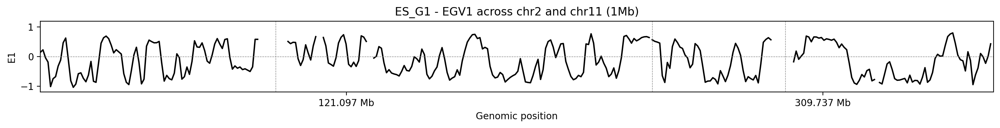

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/EGV1_ES_S_chr2_chr11.pdf


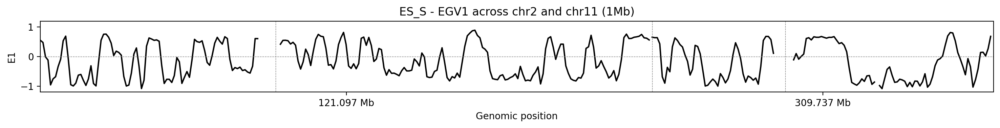

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/EGV1_ES_G2M_chr2_chr11.pdf


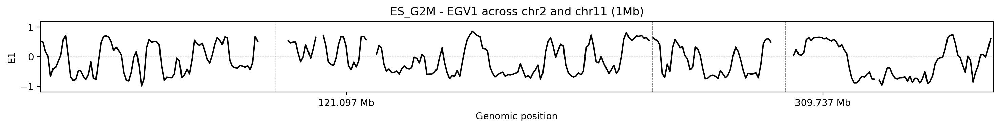

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/EGV1_ES_weighted_merge_chr2_chr11.pdf


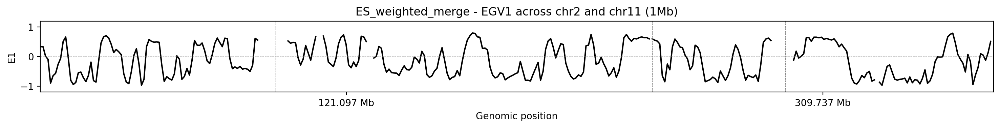

In [125]:
#plot chr2 and chr11
# Define your target arms in order
arm_order = ['chr2_p', 'chr2_q', 'chr11_p', 'chr11_q']
save_dir = "/home/xiangru.huo-umw/scHiC/scripts/plot"

# Filter and sort arms accordingly
target_arms = hg38_arms[hg38_arms['name'].isin(arm_order)].copy()
target_arms['order'] = target_arms['name'].apply(lambda x: arm_order.index(x))
target_arms = target_arms.sort_values('order')

# Calculate offsets
offsets = {}
arm_boundaries = []
current_offset = 0
for row in target_arms.itertuples():
    arm_name = row.name
    start = row.start
    end = row.end
    offsets[arm_name] = current_offset
    arm_boundaries.append((arm_name, current_offset, current_offset + (end - start)))
    current_offset += end - start

# Calculate midpoints for x-ticks per chromosome
chrom_labels = []
chrom_ticks = []
for chrom in ['chr2', 'chr11']:
    chrom_arms = [a for a in arm_boundaries if a[0].startswith(chrom)]
    if chrom_arms:
        start_pos = chrom_arms[0][1]
        end_pos = chrom_arms[-1][2]
        chrom_labels.append(chrom)
        chrom_ticks.append((start_pos + end_pos) // 2)

# Plot per condition
for cond in conditions:
    fig, ax = plt.subplots(figsize=(15, 2),dpi = 200)

    for row in target_arms.itertuples():
        arm_name = row.name
        chrom = row.chrom
        start = row.start
        end = row.end
        offset = offsets[arm_name]

        # Select E1 for the region
        loc_eig = bioframe.select(eigs[cond], (chrom, start, end)).copy()
        loc_eig['offset_pos'] = loc_eig['start'] + offset - start

        # Plot in black
        ax.plot(loc_eig['offset_pos'], loc_eig['E1'], color='black')

    # Draw boundary lines between arms
    for _, _, right in arm_boundaries[:-1]:
        ax.axvline(right, color='gray', linestyle='--', linewidth=0.5)

    # Axis formatting
    ax.axhline(0, ls='--', lw=0.5, color='gray')
    ax.set_ylabel('E1')
    ax.set_xlabel('Genomic position')
    ax.set_title(f"{samplePlotNames[cond]} - EGV1 across chr2 and chr11 (1Mb)")
    ax.set_xticks(chrom_ticks)
    ax.set_xticklabels(chrom_labels)
    ax.set_ylim(-1.2, 1.2)
    ax.set_xlim(left=0, right=current_offset)  # Ensure x-axis is tight to content
    ax.margins(x=0, y=0)  # Remove any automatic padding
    
    ax.xaxis.set_major_formatter(EngFormatter('b'))

    plt.tight_layout()
    
    save_path = os.path.join(save_dir, f"EGV1_{cond}_chr2_chr11.pdf")
    plt.savefig(save_path, format="pdf", bbox_inches="tight")
    print(f"Saved: {save_path}")
    
    plt.show()

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/EGV1_ES_chr2.pdf


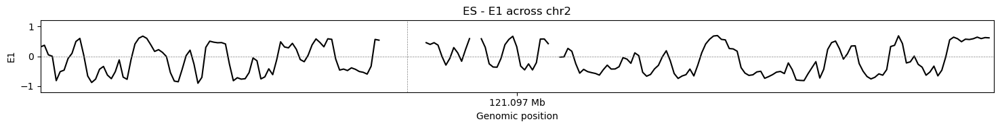

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/EGV1_DE_chr2.pdf


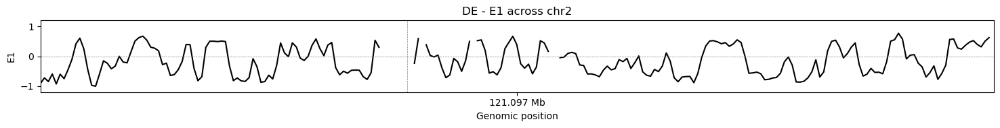

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/EGV1_HB_chr2.pdf


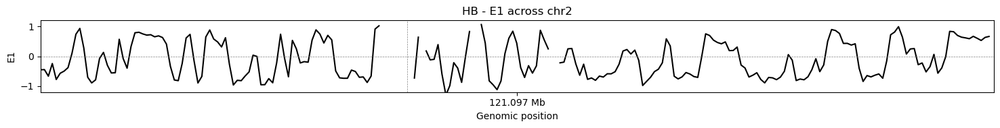

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/EGV1_iHep_chr2.pdf


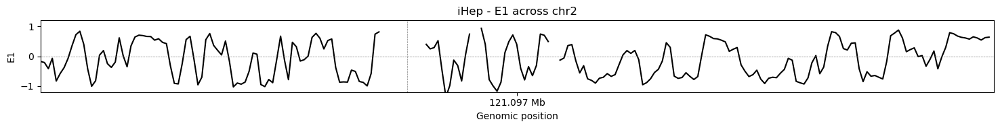

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/EGV1_mHep_chr2.pdf


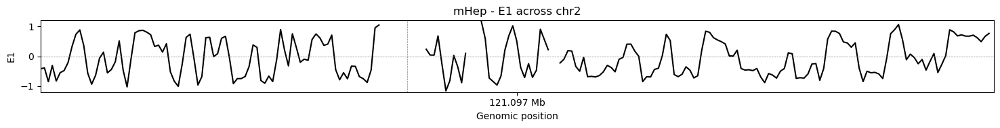

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/EGV1_ES_G1_chr2.pdf


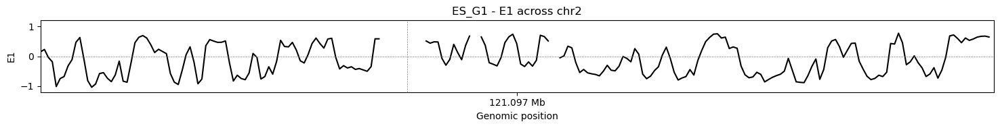

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/EGV1_ES_S_chr2.pdf


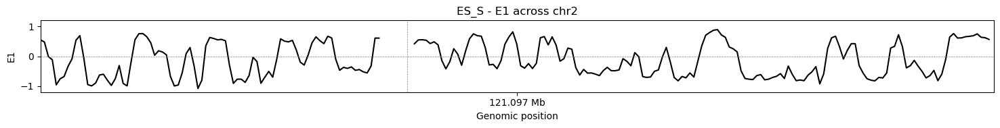

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/EGV1_ES_G2M_chr2.pdf


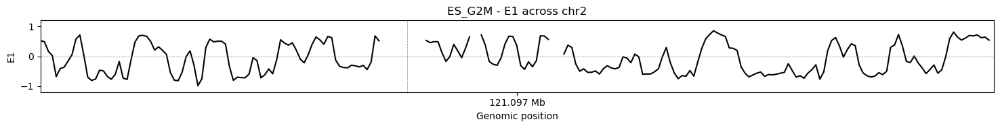

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/EGV1_ES_weighted_merge_chr2.pdf


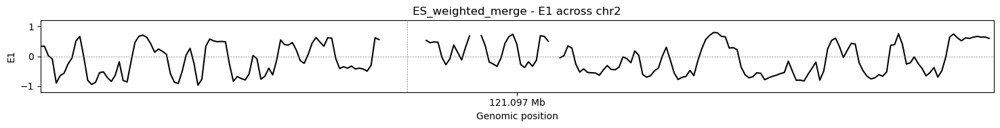

In [126]:
#plot chr2 only
# Target arms for chr2 only
arm_order_chr2 = ['chr2_p', 'chr2_q']

# Filter hg38_arms to just chr2 arms
target_arms_chr2 = hg38_arms[hg38_arms['name'].isin(arm_order_chr2)].copy()
target_arms_chr2['order'] = target_arms_chr2['name'].apply(lambda x: arm_order_chr2.index(x))
target_arms_chr2 = target_arms_chr2.sort_values('order')

# Calculate offsets for concatenating arms
offsets_chr2 = {}
arm_boundaries_chr2 = []
current_offset = 0
for row in target_arms_chr2.itertuples():
    arm_name = row.name
    start = row.start
    end = row.end
    offsets_chr2[arm_name] = current_offset
    arm_boundaries_chr2.append((arm_name, current_offset, current_offset + (end - start)))
    current_offset += end - start

# Midpoint tick for chr2
chrom_tick_chr2 = [(arm_boundaries_chr2[0][1] + arm_boundaries_chr2[-1][2]) // 2]

# Plot E1 for chr2 only
for cond in conditions:
    fig, ax = plt.subplots(figsize=(15, 2))

    for row in target_arms_chr2.itertuples():
        arm_name = row.name
        chrom = row.chrom
        start = row.start
        end = row.end
        offset = offsets_chr2[arm_name]

        # Select E1 and shift coordinates
        loc_eig = bioframe.select(eigs[cond], (chrom, start, end)).copy()
        loc_eig['offset_pos'] = loc_eig['start'] + offset - start

        # Plot in black
        ax.plot(loc_eig['offset_pos'], loc_eig['E1'], color='black')

    # Arm boundary line (optional)
    for _, _, right in arm_boundaries_chr2[:-1]:
        ax.axvline(right, color='gray', linestyle='--', linewidth=0.5)

    # Format axis
    ax.axhline(0, ls='--', lw=0.5, color='gray')
    ax.set_ylabel('E1')
    ax.set_xlabel('Genomic position')
    ax.set_title(f"{samplePlotNames[cond]} - E1 across chr2")
    ax.set_xticks(chrom_tick_chr2)
    ax.set_xticklabels(['chr2'])
    ax.set_ylim(-1.2, 1.2)
    ax.set_xlim(0, current_offset)
    ax.margins(x=0, y=0)
    ax.xaxis.set_major_formatter(EngFormatter('b'))

    plt.tight_layout()
    
    save_path = os.path.join(save_dir, f"EGV1_{cond}_chr2.pdf")
    plt.savefig(save_path, format="pdf", bbox_inches="tight")
    print(f"Saved: {save_path}")

    plt.show()

# Saddle plot

In [12]:
#saddle plot setting
# Parameters
Q_LO = 0.025
Q_HI = 0.975
N_GROUPS = 38

# To store results
expected_dict = {}
saddle_sum = {}
saddle_count = {}

# Compute expected & saddle values for each condition
for cond in conditions:
    clr = clrs[cond]
    eigenvector_track = eigs[cond][['chrom', 'start', 'end', 'E1']]

    expected = cooltools.expected_cis(clr, view_df=hg38_arms)
    expected_dict[cond] = expected

    interaction_sum, interaction_count = cooltools.saddle(
        clr,
        expected,
        eigenvector_track,
        'cis',
        n_bins=N_GROUPS,
        qrange=(Q_LO, Q_HI),
        view_df=hg38_arms
    )
    saddle_sum[cond] = interaction_sum
    saddle_count[cond] = interaction_count

In [13]:
#define the function of saddleplot
import warnings
from cytoolz import merge

def saddleplot(
    track,
    saddledata,
    n_bins,
    vrange=None,
    qrange=(0.0, 1.0),
    cmap="coolwarm",
    scale="log",
    vmin=0.5,
    vmax=2,
    color=None,
    title=None,
    xlabel=None,
    ylabel=None,
    clabel=None,
    fig=None,
    fig_kws=None,
    heatmap_kws=None,
    margin_kws=None,
    cbar_kws=None,
    subplot_spec=None,
):
    """
    Generate a saddle plot.
    Parameters
    ----------
    track : pd.DataFrame
        See cooltools.digitize() for details.
    saddledata : 2D array-like
        Saddle matrix produced by `make_saddle`. It will include 2 flanking
        rows/columns for outlier signal values, thus the shape should be
        `(n+2, n+2)`.
    cmap : str or matplotlib colormap
        Colormap to use for plotting the saddle heatmap
    scale : str
        Color scaling to use for plotting the saddle heatmap: log or linear
    vmin, vmax : float
        Value limits for coloring the saddle heatmap
    color : matplotlib color value
        Face color for margin bar plots
    fig : matplotlib Figure, optional
        Specified figure to plot on. A new figure is created if none is
        provided.
    fig_kws : dict, optional
        Passed on to `plt.Figure()`
    heatmap_kws : dict, optional
        Passed on to `ax.imshow()`
    margin_kws : dict, optional
        Passed on to `ax.bar()` and `ax.barh()`
    cbar_kws : dict, optional
        Passed on to `plt.colorbar()`
    subplot_spec : GridSpec object
        Specify a subregion of a figure to using a GridSpec.
    Returns
    -------
    Dictionary of axes objects.
    """

#     warnings.warn(
#         "Generating a saddleplot will be deprecated in future versions, "
#         + "please see https://github.com/open2c_examples for examples on how to plot saddles.",
#         DeprecationWarning,
#     )

    from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
    from matplotlib.colors import Normalize, LogNorm
    from matplotlib import ticker
    import matplotlib.pyplot as plt

    class MinOneMaxFormatter(ticker.LogFormatter):
        def set_locs(self, locs=None):
            self._sublabels = set([vmin % 10 * 10, vmax % 10, 1])

        def __call__(self, x, pos=None):
            if x not in [vmin, 1, vmax]:
                return ""
            else:
                return "{x:g}".format(x=x)

    track_value_col = track.columns[3]
    track_values = track[track_value_col].values

    digitized_track, binedges = cooltools.digitize(
        track, n_bins, vrange=vrange, qrange=qrange
    )
    x = digitized_track[digitized_track.columns[3]].values.astype(int).copy()
    x = x[(x > -1) & (x < len(binedges) + 1)]

    # Old version
    # hist = np.bincount(x, minlength=len(binedges) + 1)

    groupmean = track[track.columns[3]].groupby(digitized_track[digitized_track.columns[3]]).mean()

    if qrange is not None:
        lo, hi = qrange
        binedges = np.linspace(lo, hi, n_bins + 1)

    # Barplot of mean values and saddledata are flanked by outlier bins
    n = saddledata.shape[0]
    X, Y = np.meshgrid(binedges, binedges)
    C = saddledata
    if (n - n_bins) == 2:
        C = C[1:-1, 1:-1]
        groupmean = groupmean[1:-1]

    # Layout
    if subplot_spec is not None:
        GridSpec = partial(GridSpecFromSubplotSpec, subplot_spec=subplot_spec)
    grid = {}
    gs = GridSpec(
        nrows=3,
        ncols=3,
        width_ratios=[0.2, 1, 0.1],
        height_ratios=[0.2, 1, 0.1],
        wspace=0.05,
        hspace=0.05,
    )

    # Figure
    if fig is None:
        fig_kws_default = dict(figsize=(5, 5))
        fig_kws = merge(fig_kws_default, fig_kws if fig_kws is not None else {})
        fig = plt.figure(**fig_kws)

    # Heatmap
    if scale == "log":
        norm = LogNorm(vmin=vmin, vmax=vmax)
    elif scale == "linear":
        norm = Normalize(vmin=vmin, vmax=vmax)
    else:
        raise ValueError("Only linear and log color scaling is supported")

    grid["ax_heatmap"] = ax = plt.subplot(gs[4])
    heatmap_kws_default = dict(cmap="coolwarm", rasterized=True)
    heatmap_kws = merge(
        heatmap_kws_default, heatmap_kws if heatmap_kws is not None else {}
    )
    img = ax.pcolormesh(X, Y, C, norm=norm, **heatmap_kws)
    plt.gca().yaxis.set_visible(False)

    # Margins
    margin_kws_default = dict(edgecolor="k", facecolor=color, linewidth=1)
    margin_kws = merge(margin_kws_default, margin_kws if margin_kws is not None else {})
    # left margin hist
    grid["ax_margin_y"] = plt.subplot(gs[3], sharey=grid["ax_heatmap"])

    plt.barh(
        binedges, height=1/len(binedges), width=groupmean, align="edge", **margin_kws
    )

    plt.xlim(plt.xlim()[1], plt.xlim()[0])  # fliplr
    plt.ylim(hi, lo)
    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["bottom"].set_visible(False)
    plt.gca().spines["left"].set_visible(False)
    plt.gca().xaxis.set_visible(False)
    # top margin hist
    grid["ax_margin_x"] = plt.subplot(gs[1], sharex=grid["ax_heatmap"])

    plt.bar(
        binedges, width=1/len(binedges), height=groupmean, align="edge", **margin_kws
    )

    plt.xlim(lo, hi)
    # plt.ylim(plt.ylim())  # correct
    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)
    plt.gca().spines["left"].set_visible(False)
    plt.gca().xaxis.set_visible(False)
    plt.gca().yaxis.set_visible(False)

#     # Colorbar
    grid["ax_cbar"] = plt.subplot(gs[5])
    cbar_kws_default = dict(fraction=0.8, label=clabel or "")
    cbar_kws = merge(cbar_kws_default, cbar_kws if cbar_kws is not None else {})
    if scale == "linear" and vmin is not None and vmax is not None:
        grid["ax_cbar"] = cb = plt.colorbar(img, **cbar_kws)
        # cb.set_ticks(np.arange(vmin, vmax + 0.001, 0.5))
        # # do linspace between vmin and vmax of 5 segments and trunc to 1 decimal:
        decimal = 10
        nsegments = 5
        cd_ticks = np.trunc(np.linspace(vmin, vmax, nsegments) * decimal) / decimal
        cb.set_ticks(cd_ticks)
    else:
        print('cbar')

        cb = plt.colorbar(img, format=MinOneMaxFormatter(), cax=grid["ax_cbar"], **cbar_kws)
        cb.ax.yaxis.set_minor_formatter(MinOneMaxFormatter())

    # extra settings
    grid["ax_heatmap"].set_xlim(lo, hi)
    grid["ax_heatmap"].set_ylim(hi, lo)
    grid['ax_heatmap'].grid(False)
    if title is not None:
        grid["ax_margin_x"].set_title(title)
    if xlabel is not None:
        grid["ax_heatmap"].set_xlabel(xlabel)
    if ylabel is not None:
        grid["ax_margin_y"].set_ylabel(ylabel)
        
    return grid

cbar
cbar
cbar
cbar
cbar
cbar
cbar
cbar
cbar


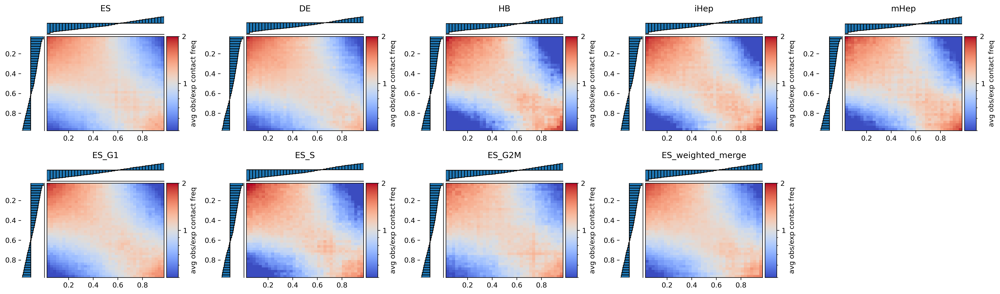

In [ ]:
#plot saddle plot
save_dir = "/home/xiangru.huo-umw/scHiC/scripts/plot"
save_path = f"{save_dir}/saddleplot_all_conditions_grid.pdf"

# Set up 2 rows × 5 columns
n_rows = 2
n_cols = 5
fig = plt.figure(figsize=(4 * n_cols, 3 * n_rows), dpi=300)
gs = GridSpec(nrows=n_rows, ncols=n_cols, figure=fig)

# Plot all conditions
for idx, cond in enumerate(conditions):
    row = idx // n_cols
    col = idx % n_cols
    subplot_spec = gs[row, col]

    # Calculate saddle average
    saddle_avg = saddle_sum[cond] / saddle_count[cond]

    # Plot saddle in assigned grid
    grid = saddleplot(
        eigs[cond][['chrom', 'start', 'end', 'E1']],
        saddle_avg,
        N_GROUPS,
        qrange=(Q_LO, Q_HI),
        title=samplePlotNames[cond],
        cbar_kws={'label': 'avg obs/exp contact freq'},
        subplot_spec=subplot_spec,
        fig=fig
    )

plt.tight_layout()
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

# saddle strength

In [17]:
from matplotlib.cm import get_cmap
from cooltools.api.saddle import saddle_strength

In [18]:
#define the function of compartment strength of AA or BB
def saddle_strength_AA(S, C):
    """
    Parameters
    ----------
    S, C : 2D arrays, square, same shape
        Saddle sums and counts, respectively

    Returns
    -------
    1D array
    Ratios of cumulative corner interaction scores, where the saddle data is
    grouped over the AA corners and AB+BA corners with increasing extent.

    """
    m, n = S.shape
    if m != n:
        raise ValueError("`saddledata` should be square.")

    ratios = np.zeros(n)
    for k in range(1, n):
        intra_sum = np.nansum(S[n - k : n, n - k : n])
        intra_count = np.nansum(C[n - k : n, n - k : n])
        intra = intra_sum / intra_count

        inter_sum = np.nansum(S[0:k, n - k : n]) + np.nansum(S[n - k : n, 0:k])
        inter_count = np.nansum(C[0:k, n - k : n]) + np.nansum(C[n - k : n, 0:k])
        inter = inter_sum / inter_count

        ratios[k] = intra / inter
    return ratios

def saddle_strength_BB(S, C):
    """
    Parameters
    ----------
    S, C : 2D arrays, square, same shape
        Saddle sums and counts, respectively

    Returns
    -------
    1D array
    Ratios of cumulative corner interaction scores, where the saddle data is
    grouped over the BB corners and AB+BA corners with increasing extent.

    """
    m, n = S.shape
    if m != n:
        raise ValueError("`saddledata` should be square.")

    ratios = np.zeros(n)
    for k in range(1, n):
        intra_sum = np.nansum(S[0:k, 0:k])
        intra_count = np.nansum(C[0:k, 0:k])
        intra = intra_sum / intra_count

        inter_sum = np.nansum(S[0:k, n - k : n]) + np.nansum(S[n - k : n, 0:k])
        inter_count = np.nansum(C[0:k, n - k : n]) + np.nansum(C[n - k : n, 0:k])
        inter = inter_sum / inter_count

        ratios[k] = intra / inter
    return ratios

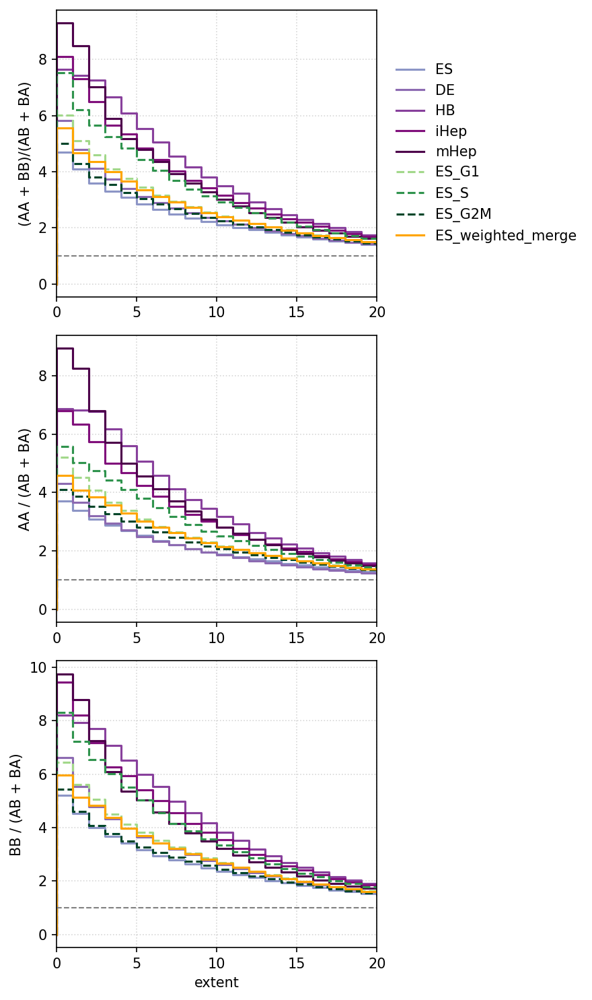

In [28]:
#plot all compartment strength at same time
# Define groups
bulk_conds = ['ES', 'DE', 'HB', 'iHep', 'mHep']
cycle_conds = ['ES_G1', 'ES_S', 'ES_G2M']

# Colors
bulk_colors = get_cmap('BuPu')(np.linspace(0.5, 1, len(bulk_conds)))
cycle_colors = get_cmap('YlGn')(np.linspace(0.4, 1, len(cycle_conds)))

# Setup
fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(6, 10), dpi=150)
x = np.arange(N_GROUPS + 2)

#set a profile to store the saddle strength
ss_profile = {}
ss_profile_AA = {}
ss_profile_BB = {}

# Loop conditions
for cond in conditions:
    ss_profile[cond]     = saddle_strength(saddle_sum[cond], saddle_count[cond])
    ss_profile_AA[cond]  = saddle_strength_AA(saddle_sum[cond], saddle_count[cond])
    ss_profile_BB[cond]  = saddle_strength_BB(saddle_sum[cond], saddle_count[cond])
    
    # Choose style
    if cond in bulk_conds:
        color = bulk_colors[bulk_conds.index(cond)]
        linestyle = '-'
    elif cond in cycle_conds:
        color = cycle_colors[cycle_conds.index(cond)]
        linestyle = '--'
    else:
        color = 'orange'
        linestyle = '-'

    # Plot each on its axis
    axs[0].step(x, ss_profile[cond],where='pre', label=samplePlotNames[cond], color=color, linestyle=linestyle)
    axs[1].step(x, ss_profile_AA[cond],where='pre', label=samplePlotNames[cond], color=color, linestyle=linestyle)
    axs[2].step(x, ss_profile_BB[cond],where='pre', label=samplePlotNames[cond], color=color, linestyle=linestyle)

# Label each plot
labels = ['(AA + BB)/(AB + BA)', 'AA / (AB + BA)', 'BB / (AB + BA)']
for i, ax in enumerate(axs):
    ax.set_xlim(0, len(x)//2)
    ax.set_ylabel(labels[i])
    ax.axhline(1, c='gray', ls='--', lw=1)
    ax.grid(True, linestyle=':', alpha=0.5)
    if i == 2:
        ax.set_xlabel('extent')

# Legend outside
axs[0].legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)

plt.tight_layout()
plt.savefig(f"{save_dir}/saddle_strength_profiles_split.pdf", bbox_inches='tight')
plt.show()

In [40]:
ss_profile_AA[cond]

array([0.        , 4.58986862, 4.08090714, 3.85672407, 3.56867595,
       3.29101259, 3.01761893, 2.81359594, 2.61191611, 2.43374249,
       2.27553179, 2.1473753 , 2.03875965, 1.93468021, 1.83106386,
       1.73984344, 1.65037866, 1.57292946, 1.4966444 , 1.43158828,
       1.37153946, 1.31654021, 1.26762515, 1.2260534 , 1.18997477,
       1.1547244 , 1.12398604, 1.0972885 , 1.07539178, 1.05717053,
       1.04133363, 1.02920265, 1.0200436 , 1.01282462, 1.0046715 ,
       0.99961041, 0.99539873, 0.99280573, 0.99409959, 0.99608879])

cbar
cbar
cbar
cbar
cbar
cbar
cbar
cbar
cbar


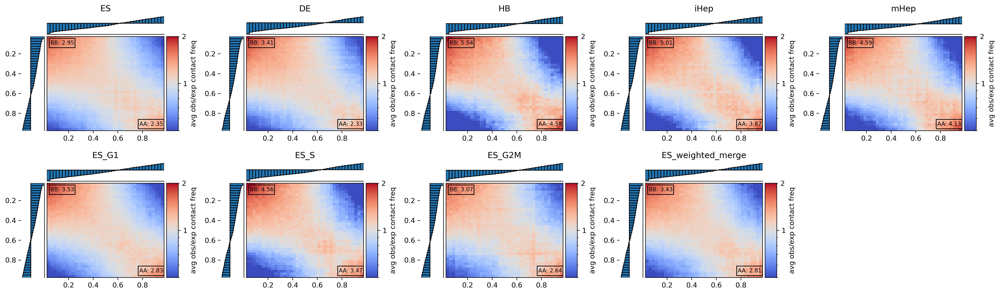

In [48]:
#Annotate the top20% compartment strength on the corner
from matplotlib.patches import Rectangle
save_dir = "/home/xiangru.huo-umw/scHiC/scripts/plot"
save_path = f"{save_dir}/saddleplot_all_conditions_grid2.pdf"

# Set up 2 rows × 5 columns
n_rows = 2
n_cols = 5
fig = plt.figure(figsize=(4 * n_cols, 3 * n_rows), dpi=300)
gs = GridSpec(nrows=n_rows, ncols=n_cols, figure=fig)

# Plot all conditions
for idx, cond in enumerate(conditions):
    row = idx // n_cols
    col = idx % n_cols
    subplot_spec = gs[row, col]

    # Calculate saddle average
    saddle_avg = saddle_sum[cond] / saddle_count[cond]

    # Plot saddle
    grid = saddleplot(
        eigs[cond][['chrom', 'start', 'end', 'E1']],
        saddle_avg,
        N_GROUPS,
        qrange=(Q_LO, Q_HI),
        title=samplePlotNames[cond],
        cbar_kws={'label': 'avg obs/exp contact freq'},
        subplot_spec=subplot_spec,
        fig=fig
    )

    ax = grid["ax_heatmap"]

    # Get strength values from top 20%
    Top = 0.2
    ss_AA = saddle_strength_AA(saddle_sum[cond], saddle_count[cond])
    ss_BB = saddle_strength_BB(saddle_sum[cond], saddle_count[cond])
    k = int(len(ss_AA) * Top) - 1
    AA_strength = ss_AA[k]
    BB_strength = ss_BB[k]

    # Label B-B in top-left
    ax.add_patch(Rectangle((0.02, 0.88), 0.22, 0.1, transform=ax.transAxes,
                           edgecolor='black', facecolor='none', lw=1))
    ax.text(0.03, 0.93, f"BB: {BB_strength:.2f}", transform=ax.transAxes,
            ha='left', va='center', fontsize=8)

    # Label A-A in bottom-right
    ax.add_patch(Rectangle((0.78, 0.02), 0.22, 0.1, transform=ax.transAxes,
                           edgecolor='black', facecolor='none', lw=1))
    ax.text(0.79, 0.07, f"AA: {AA_strength:.2f}", transform=ax.transAxes,
            ha='left', va='center', fontsize=8)

# Finalize
plt.tight_layout()
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()